# Example 15.1 – Basic PID Control for Angle Tracking
**Chapter 15 – PID Control Applied to Four-Bar Mechanisms**
Simulates the system response (I=0.05, b=0.10) with initial PID gains.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.optimize import minimize

## Discrete PID Simulation

In [ ]:
# System configuration and basic simulation
I, b, dt = 0.05, 0.10, 0.01
t = np.arange(0, 5.0, dt)
Kp, Ki, Kd = 5.0, 1.0, 0.05
theta_ref = np.pi / 3  # reference: 60°

theta = np.zeros(len(t))
omega = np.zeros(len(t))
e_int, e_prev = 0.0, 0.0

for k in range(1, len(t)):
    e = theta_ref - theta[k-1]
    e_int += e * dt
    de = (e - e_prev) / dt
    u = Kp*e + Ki*e_int + Kd*de
    alpha = (u - b*omega[k-1]) / I
    omega[k] = omega[k-1] + alpha*dt
    theta[k] = theta[k-1] + omega[k]*dt
    e_prev = e

e_final = np.degrees(theta_ref - theta[-1])
ise = trapezoid((np.degrees(theta_ref) - np.degrees(theta))**2, t)
print(f'Final Error: {e_final:.4f}°')
print(f'ISE = {ise:.4f} (°²·s)')

Final Error: -0.0386°
ISE = 648.2004 (°²·s)


## Kp Response Curve and Analysis

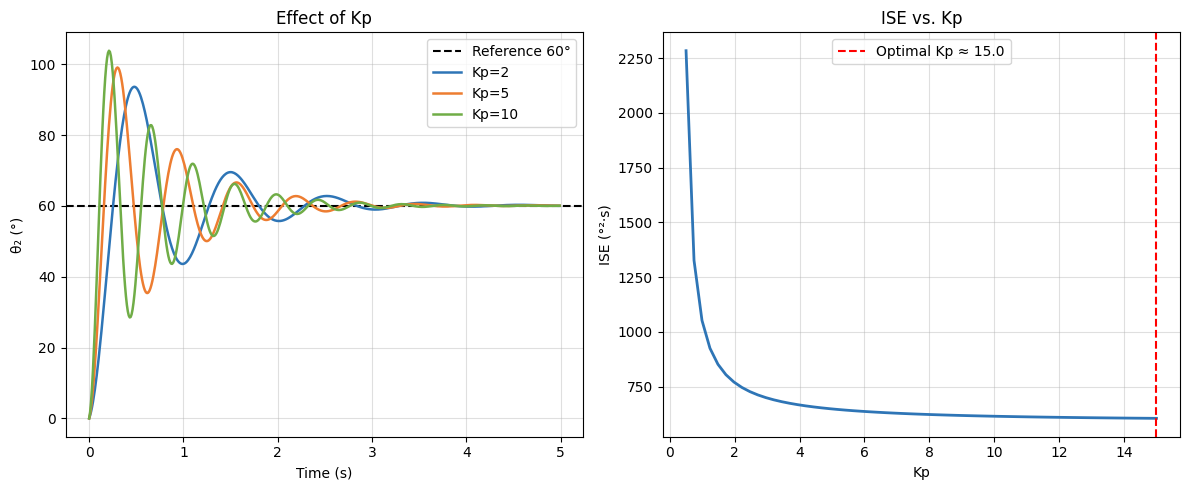

In [ ]:
# Analysis of the effect of Kp and ISE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ref_deg = np.degrees(theta_ref)
Kp_vals = [2.0, 5.0, 10.0]
colors = ['#2E75B6', '#ED7D31', '#70AD47']

def sim_pid(Kp, Ki=1.0, Kd=0.05, I=0.05, b=0.10, dt=0.01, t_end=5.0):
    t_ = np.arange(0, t_end, dt)
    th = np.zeros(len(t_)); om = np.zeros(len(t_))
    ei, ep = 0.0, 0.0
    ref_ = np.pi/3
    for k in range(1, len(t_)):
        e_ = ref_ - th[k-1]
        ei += e_*dt; de_ = (e_-ep)/dt
        u_ = Kp*e_ + Ki*ei + Kd*de_
        al = (u_ - b*om[k-1])/I
        om[k] = om[k-1]+al*dt; th[k] = th[k-1]+om[k]*dt; ep=e_
    return t_, th

ax = axes[0]
ax.axhline(60, color='k', ls='--', lw=1.5, label='Reference 60°')
for Kp_, lbl, c in zip(Kp_vals, ['Kp=2','Kp=5','Kp=10'], colors):
    t_, th_ = sim_pid(Kp_)
    ax.plot(t_, np.degrees(th_), color=c, lw=1.8, label=lbl)
ax.set_xlabel('Time (s)')
ax.set_ylabel('θ₂ (°)')
ax.set_title('Effect of Kp')
ax.legend()
ax.grid(alpha=0.4)

kp_range = np.linspace(0.5, 15, 60)
ise_v = []
for Kp_ in kp_range:
    t_, th_ = sim_pid(Kp_)
    ise_v.append(trapezoid((60 - np.degrees(th_))**2, t_))
ise_v = np.array(ise_v)

ax2 = axes[1]
ax2.plot(kp_range, ise_v, color='#2E75B6', lw=2)
ax2.axvline(kp_range[np.argmin(ise_v)], color='red', ls='--', label=f'Optimal Kp ≈ {kp_range[np.argmin(ise_v)]:.1f}')
ax2.set_xlabel('Kp')
ax2.set_ylabel('ISE (°²·s)')
ax2.set_title('ISE vs. Kp')
ax2.legend()
ax2.grid(alpha=0.4)

plt.tight_layout()
plt.show()

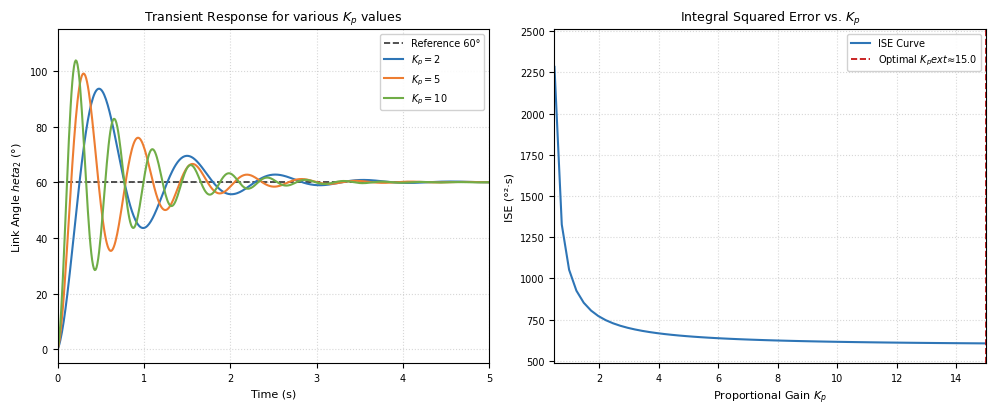

In [4]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# Dynamic naming block
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex15_1_basic_pid"
except Exception:
    notebook_name = "ex15_1_basic_pid"

# Configure Springer publishing graphics standards
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']
plt.rcParams['font.size'] = 8
plt.rcParams['axes.labelsize'] = 8
plt.rcParams['axes.titlesize'] = 9
plt.rcParams['legend.fontsize'] = 7
plt.rcParams['xtick.labelsize'] = 7
plt.rcParams['ytick.labelsize'] = 7

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ref_deg = 60.0
Kp_vals = [2.0, 5.0, 10.0]
colors = ['#2E75B6', '#ED7D31', '#70AD47']

# Local simulation helper with default model params
def sim_pid(Kp, Ki=1.0, Kd=0.05, I=0.05, b=0.10, dt=0.01, t_end=5.0):
    t_ = np.arange(0, t_end, dt)
    th = np.zeros(len(t_))
    om = np.zeros(len(t_))
    ei, ep = 0.0, 0.0
    ref_ = np.pi / 3
    for k in range(1, len(t_)):
        e_ = ref_ - th[k-1]
        ei += e_ * dt
        de_ = (e_ - ep) / dt
        u_ = Kp * e_ + Ki * ei + Kd * de_
        al = (u_ - b * om[k-1]) / I
        om[k] = om[k-1] + al * dt
        th[k] = th[k-1] + om[k] * dt
        ep = e_
    return t_, th

# Subplot 1: Dynamic Transient Response
ax1 = axes[0]
ax1.axhline(ref_deg, color='k', ls='--', lw=1.2, label='Reference 60°', alpha=0.8)
for Kp_, lbl, c in zip(Kp_vals, ['$K_p = 2$', '$K_p = 5$', '$K_p = 10$'], colors):
    t_, th_ = sim_pid(Kp_)
    ax1.plot(t_, np.degrees(th_), color=c, lw=1.5, label=lbl)

ax1.set_xlabel('Time (s)')
ax1.set_ylabel(r'Link Angle $	heta_2$ (°)')
ax1.set_title('Transient Response for various $K_p$ values')
ax1.set_xlim([0, 5.0])
ax1.set_ylim([-5, 115])  # Expand margins dynamically to prevent label overlap
ax1.grid(True, which='both', ls=':', alpha=0.5)
ax1.legend(loc='upper right', frameon=True, framealpha=0.9)

# Subplot 2: Integral Squared Error (ISE)
kp_range = np.linspace(0.5, 15, 60)
ise_v = []
for Kp_ in kp_range:
    t_, th_ = sim_pid(Kp_)
    ise_v.append(trapezoid((60 - np.degrees(th_))**2, t_))
ise_v = np.array(ise_v)

opt_kp = kp_range[np.argmin(ise_v)]

ax2 = axes[1]
ax2.plot(kp_range, ise_v, color='#2E75B6', lw=1.5, label='ISE Curve')
ax2.axvline(opt_kp, color='#C00000', ls='--', lw=1.2, label=rf'Optimal $K_p 	ext{{≈}} {opt_kp:.1f}$')
ax2.set_xlabel(r'Proportional Gain $K_p$')
ax2.set_ylabel('ISE (°²·s)')
ax2.set_title('Integral Squared Error vs. $K_p$')
ax2.set_xlim([0.5, 15.0])
ax2.set_ylim([np.min(ise_v) * 0.8, np.max(ise_v) * 1.1])
ax2.grid(True, which='both', ls=':', alpha=0.5)
ax2.legend(loc='upper right', frameon=True, framealpha=0.9)

plt.tight_layout()

# Mandatory Springer Export Block
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

## PID Parameter Optimization to Minimize ISE

In [5]:
# Optimization of PID parameters using Nelder-Mead
import numpy as np
from scipy.integrate import trapezoid
from scipy.optimize import minimize

I, b, dt = 0.05, 0.10, 0.01
t = np.arange(0, 5.0, dt)
theta_ref = np.pi / 3  # 60 degrees

def run_simulation(gains):
    Kp, Ki, Kd = gains
    theta = np.zeros(len(t))
    omega = np.zeros(len(t))
    e_int, e_prev = 0.0, 0.0

    for k in range(1, len(t)):
        e = theta_ref - theta[k-1]
        e_int += e * dt
        de = (e - e_prev) / dt
        u = Kp*e + Ki*e_int + Kd*de
        alpha = (u - b*omega[k-1]) / I
        omega[k] = omega[k-1] + alpha*dt
        theta[k] = theta[k-1] + omega[k]*dt
        e_prev = e
    return t, theta

def objective_function(gains):
    _, theta = run_simulation(gains)
    ise = trapezoid((np.degrees(theta_ref) - np.degrees(theta))**2, t)
    penalty = 0.0
    for g in gains:
        if g < 0:
            penalty += 100000.0 * (abs(g) + 1)
    return ise + penalty

initial_gains = [5.0, 1.0, 0.05]
result = minimize(objective_function, initial_gains, method='Nelder-Mead')
optimal_gains = result.x

print("Optimization Results:")
print(f"Optimal Kp: {optimal_gains[0]:.4f}")
print(f"Optimal Ki: {optimal_gains[1]:.4f}")
print(f"Optimal Kd: {optimal_gains[2]:.4f}")
print(f"Minimum ISE obtained: {result.fun:.4f} (°²·s)")

Optimization Results:
Optimal Kp: 10.0001
Optimal Ki: 0.0001
Optimal Kd: 4.9000
Minimum ISE obtained: 18.0000 (°²·s)


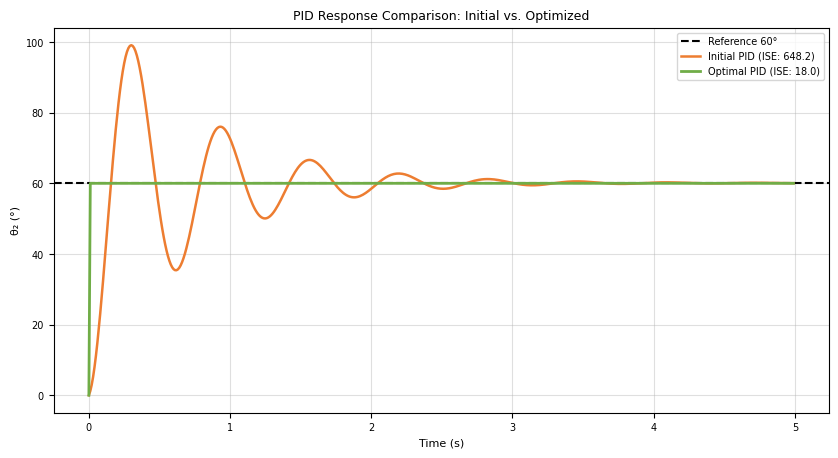

In [6]:
# Comparison of original vs optimized response
import numpy as np
import matplotlib.pyplot as plt

t_init, theta_init = run_simulation(initial_gains)
t_opt, theta_opt = run_simulation(optimal_gains)

plt.figure(figsize=(10, 5))
plt.axhline(60, color='k', ls='--', lw=1.5, label='Reference 60°')
plt.plot(t_init, np.degrees(theta_init), label=f'Initial PID (ISE: {objective_function(initial_gains):.1f})', color='#ED7D31', lw=1.8)
plt.plot(t_opt, np.degrees(theta_opt), label=f'Optimal PID (ISE: {result.fun:.1f})', color='#70AD47', lw=2)
plt.xlabel('Time (s)')
plt.ylabel('θ₂ (°)')
plt.title('PID Response Comparison: Initial vs. Optimized')
plt.legend()
plt.grid(alpha=0.4)
plt.show()